<a href="https://colab.research.google.com/github/freddy-7/TI3002C/blob/main/10_ANOVA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
%pip install statsmodels

In [3]:
#Cargamos librerias
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from statsmodels.formula.api import ols
from scipy import stats
from statsmodels.graphics.factorplots import interaction_plot

In [4]:
#Cargar archivo csv 
df=pd.read_csv("Titanic.csv")

In [5]:
#Rellenamos nulos
df = df.bfill()
df = df.ffill()

In [ ]:
df.info()

<Axes: title={'center': 'Fare'}, xlabel='Pclass'>

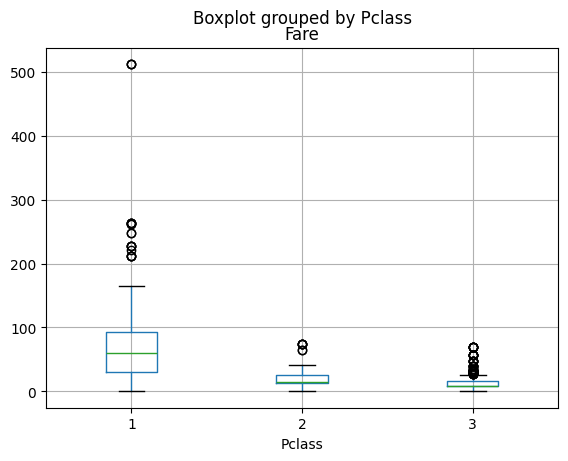

In [7]:
#Analizamos los diagrama de caja de la variable objetivo "tarifa" por cada categoria 
# de la variable independiente "pclass"
df.boxplot("Fare", by= "Pclass")

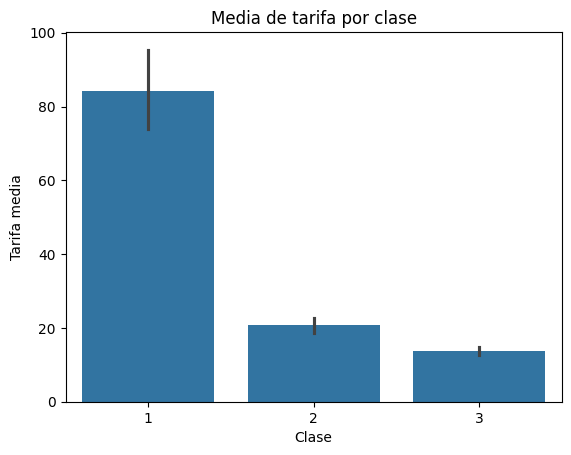

In [14]:
# Gráfico de barras con barras de error (por defecto muestra el IC al 95%)
sns.barplot(data=df, x="Pclass", y="Fare", errorbar=('ci', 95))
plt.title("Media de tarifa por clase")
plt.ylabel("Tarifa media")
plt.xlabel("Clase")
plt.show()

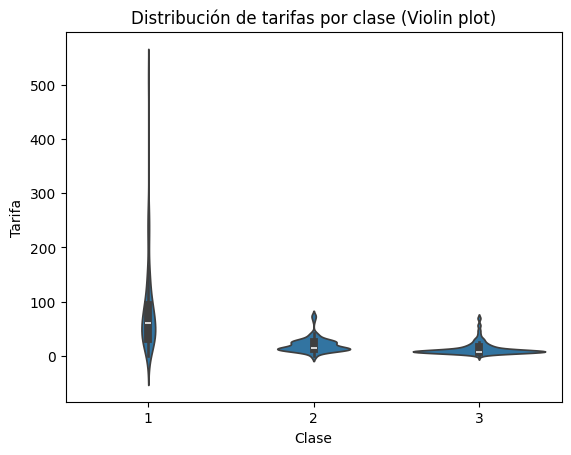

In [15]:
# Gráfico de violín
sns.violinplot(data=df, x="Pclass", y="Fare", inner="box")
plt.title("Distribución de tarifas por clase (Violin plot)")
plt.ylabel("Tarifa")
plt.xlabel("Clase")
plt.show()

In [16]:
#Obtengo las categorías de la variable (pclass)
grupos=pd.unique(df['Pclass'].values)
grupos

array([3, 1, 2])

**SCIPY ONEWAY (ANOVA)**

In [17]:
#Defino grupos donde me entrega la columna Fare separada por grupos de las 
#categorías de la columna pclass: "1", "2" y "3" 
Fare_1= df.Fare[df.Pclass==1]
Fare_2= df.Fare[df.Pclass==2]
Fare_3= df.Fare[df.Pclass==3]


In [18]:
#p-value < 0.05, se rechaza la hipótesis de que todas las medias son iguales
#p-value < 0.05, implica que la variable categórica influye en la variable 
# cuantitativa
anova= stats.f_oneway(Fare_1, Fare_2, Fare_3)
anova

F_onewayResult(statistic=np.float64(242.34415651744814), pvalue=np.float64(1.031376320913912e-84))

**STATESMODELS (ANOVA)**

In [19]:
#p-value < 0.05, se rechaza la hipótesis de que todas las medias son iguales
mod= ols('Fare ~ Pclass', data=df).fit()
anova_table=sm.stats.anova_lm(mod, typ=1)
print (anova_table)

             df        sum_sq        mean_sq           F        PR(>F)
Pclass      1.0  6.636250e+05  663624.976929  384.547434  1.967386e-71
Residual  889.0  1.534174e+06    1725.729827         NaN           NaN


In [20]:
#p-value < 0.05, se rechaza la hipótesis de que todas las medias son iguales
# Se puede generar un analisis ANOVA Factorial (Múltiples factores con interacción)
mod= ols('Fare ~ Sex + Pclass + Sex:Pclass', data=df).fit()
anova_table=sm.stats.anova_lm(mod, typ=1)
print (anova_table)

               df        sum_sq        mean_sq           F        PR(>F)
Sex           1.0  7.306640e+04   73066.397308   44.352450  4.805283e-11
Pclass        1.0  6.175508e+05  617550.791669  374.863021  6.244332e-70
Sex:Pclass    1.0  4.593437e+04   45934.370325   27.882884  1.621976e-07
Residual    887.0  1.461247e+06    1647.403871         NaN           NaN


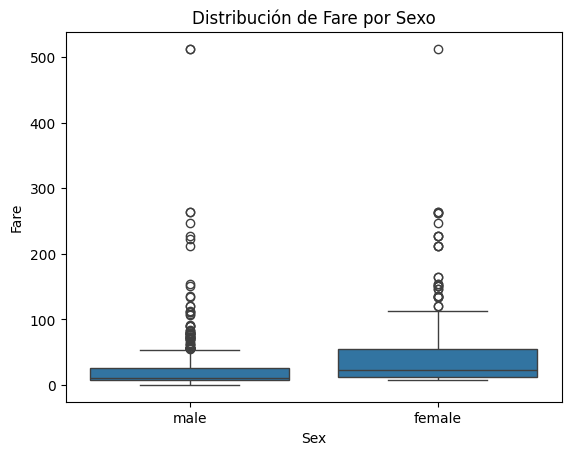

In [21]:
#Grafica variable fare vs sex
sns.boxplot(data=df, x='Sex', y='Fare')
plt.title("Distribución de Fare por Sexo")
plt.show()


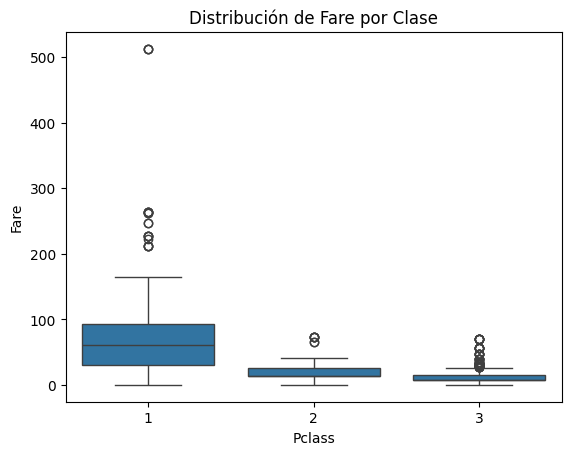

In [22]:
#Grafica variable fare vs pclass
sns.boxplot(data=df, x='Pclass', y='Fare')
plt.title("Distribución de Fare por Clase")
plt.show()

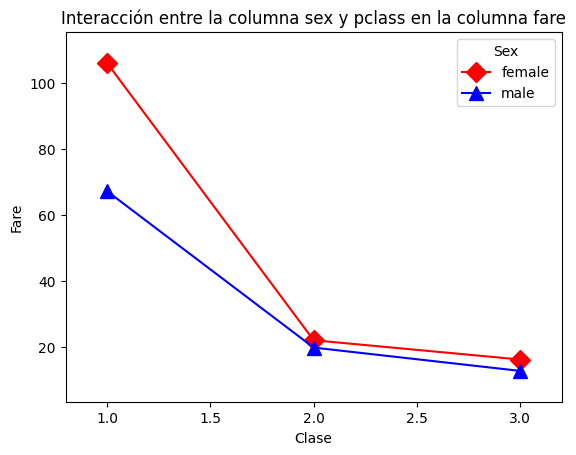

In [23]:
fig = interaction_plot(df['Pclass'], df['Sex'], df['Fare'],
                       colors=['red', 'blue'], markers=['D', '^'], ms=10)
plt.title("Interacción entre la columna sex y pclass en la columna fare")
plt.xlabel("Clase")
plt.ylabel("Fare")
plt.show()